In [1]:
import matplotlib.pyplot as plt
import numpy as np

from agents import EpsilonGreedyAgent, UCBAgent, GradientBanditAgent
from estimators import ConstantStepSizeEstimator, SampleAverageEstimator
from simulation import run_experiment_parallel

%load_ext autoreload
%autoreload 2

# Non-Stationary k-armed Bandit Testbed

In [2]:
# Bandit parameters
k = 10  # number of arms in the bandit
q_true_mean = 0.0
q_true_var = 0.0  # or should this be 1.0?
drift_var = 0.01

# Simulation parameters
T = 10000  # number of timesteps played
R = 2000   # number of runs to play in the simulation

# $\epsilon$-greedy action-value method

### Constant Step Size Estimator with and without optimistic initial values

In [3]:
%%time

# Estimator and Agent parameters
estimators = [SampleAverageEstimator, ConstantStepSizeEstimator, ConstantStepSizeEstimator, ConstantStepSizeEstimator, ConstantStepSizeEstimator]
initial_qs = [0.0, 0.0, 0.0, 5.0, 5.0]
epsilons = [0.1, 0.1, 0.0, 0.1, 0.0]
labels = [
    "Sample Average ($\\epsilon = %.01f$)" % (epsilons[0]),
    "Constant Step-Size ($\\epsilon = %.01f$)" % (epsilons[1]),
    "Greedy Constant Step-Size ($\\epsilon = %.01f$)" % (epsilons[2]),
    "Optimistic Constant Step-Size ($q_0 = %.0f$, $\\epsilon = %.01f$)" % (initial_qs[3], epsilons[3]),
    "Optimistic, Greedy Constant Step-Size ($q_0 = %.0f$, $\\epsilon = %.01f$)" % (initial_qs[4], epsilons[4])
]

results = []

for estimator, initial_q, epsilon in list(zip(estimators, initial_qs, epsilons)):
    results.append(
        run_experiment_parallel(
            R, T, k, 
            estimator, 
            EpsilonGreedyAgent,
            q_true_mean=q_true_mean, q_true_var=q_true_var, drift_var=drift_var,
            initial_q=initial_q,
            epsilon=epsilon
        )
    )

CPU times: user 44.9 s, sys: 6.46 s, total: 51.3 s
Wall time: 2d 21h 5min 28s


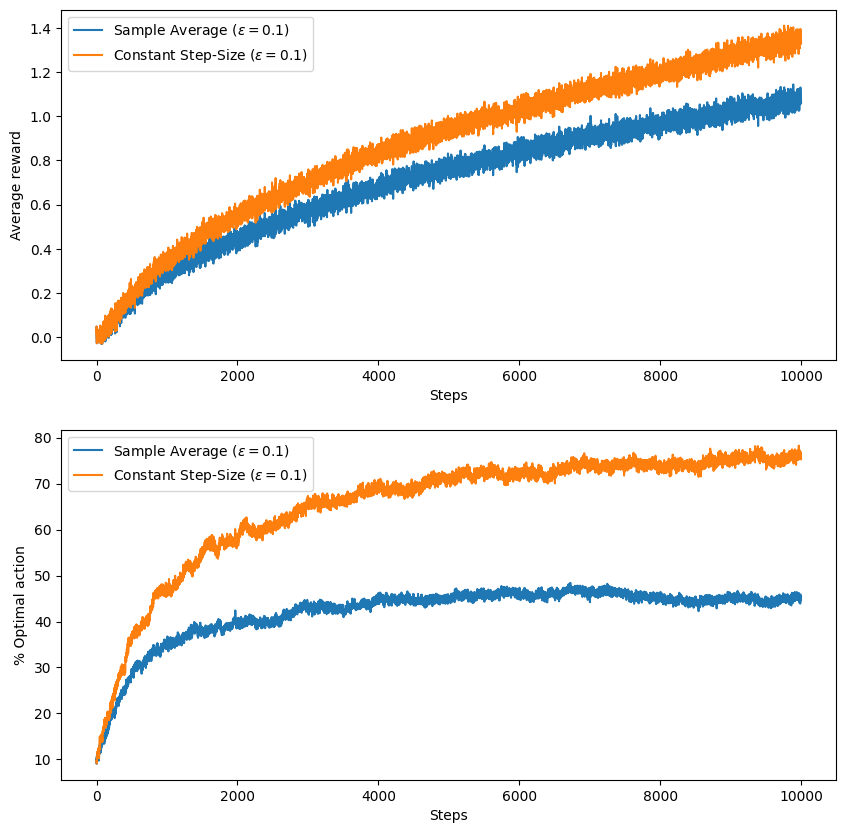

In [4]:
plt.figure(figsize=(10, 10))

plt.subplot(2, 1, 1)
for i, result in enumerate(results[0:2]):
    plt.plot(result["average_rewards"], label=labels[i])
plt.xlabel("Steps")
plt.ylabel("Average reward")
plt.legend()

plt.subplot(2, 1, 2)
for i, result in enumerate(results[0:2]):
    plt.plot(result["percent_optimal_actions"], label=labels[i])
plt.xlabel("Steps")
plt.ylabel("% Optimal action")
plt.legend()

plt.savefig('../images/figure_2_2_ns.png', bbox_inches="tight")

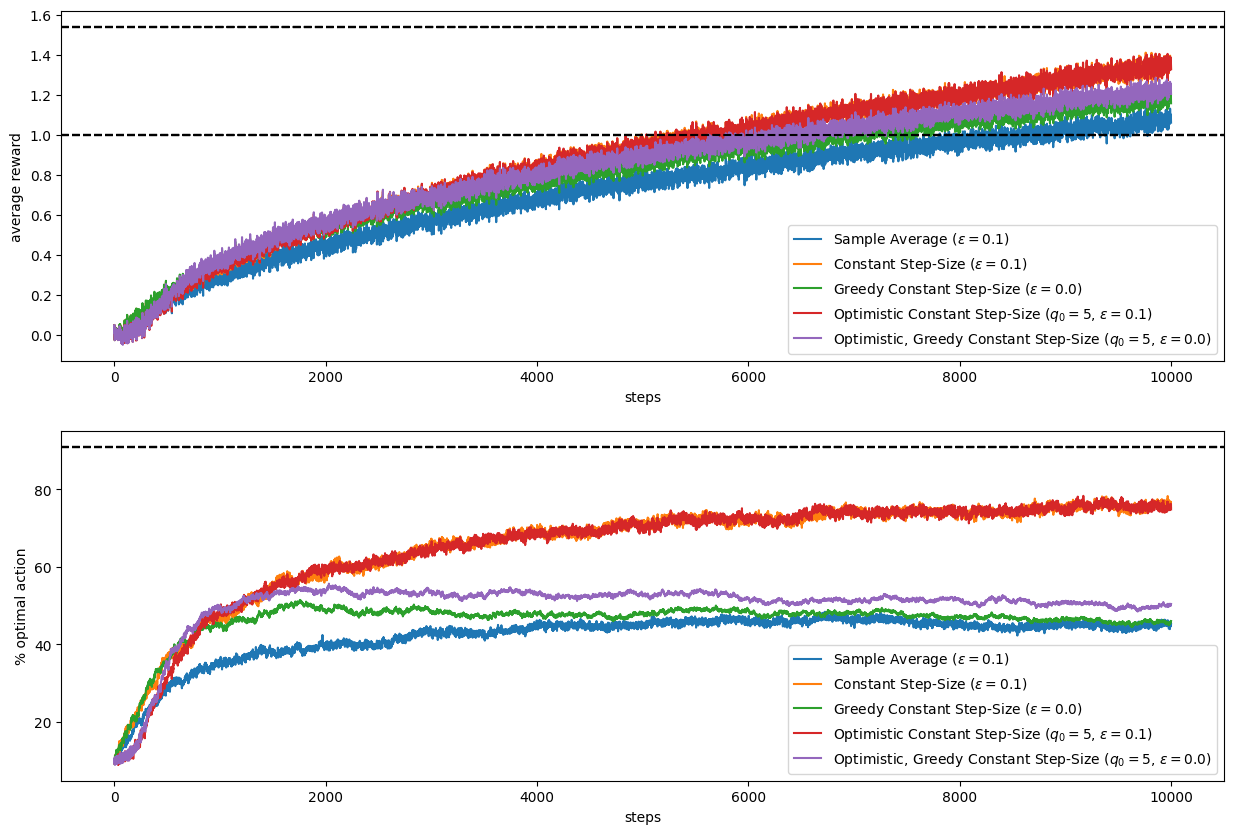

In [5]:
plt.figure(figsize=(15, 10))

plt.subplot(2, 1, 1)
for i, result in enumerate(results):
    plt.plot(result["average_rewards"], label=labels[i])
    plt.axhline(y=1.54, color='k', linestyle='--')
    plt.axhline(y=1, color='k', linestyle='--')
plt.xlabel("steps")
plt.ylabel("average reward")
plt.legend()

plt.subplot(2, 1, 2)
for i, result in enumerate(results):
    plt.plot(result["percent_optimal_actions"], label=labels[i])
    plt.axhline(y=91, color='k', linestyle='--')
plt.xlabel("steps")
plt.ylabel("% optimal action")
plt.legend()

# UCB

In [6]:
%%time

# Estimator and Agent parameters
estimators = [SampleAverageEstimator, SampleAverageEstimator, ConstantStepSizeEstimator, ConstantStepSizeEstimator]
agents =     [EpsilonGreedyAgent,     UCBAgent,               EpsilonGreedyAgent,        UCBAgent]
epsilons =   [0.1,                    None,                   0.1,                       None]
cs =         [None,                   2.0,                    None,                      2.0]
labels = [
    "Epsilon Greedy w/ Sample Average ($\\epsilon = %.01f$)" % (epsilons[0]),
    "UCB w/ Sample Average ($c = %.01f$)" % (cs[1]),
    "Epsilon Greedy w/ Constant Step-Size Estimator ($\\epsilon = %.01f$)" % (epsilons[2]),
    "UCB w/ Constant Step-Size Estimator ($c = %.01f$)" % (cs[3])
]

results = []

for estimator, agent, epsilon, c in list(zip(estimators, agents, epsilons, cs)):
    results.append(
        run_experiment_parallel(
            R, T, k, 
            estimator, 
            agent,
            q_true_mean=q_true_mean, q_true_var=q_true_var, drift_var=drift_var,
            epsilon=epsilon,
            c=c
        )
    )

CPU times: user 29.3 s, sys: 3.99 s, total: 33.3 s
Wall time: 8min 57s


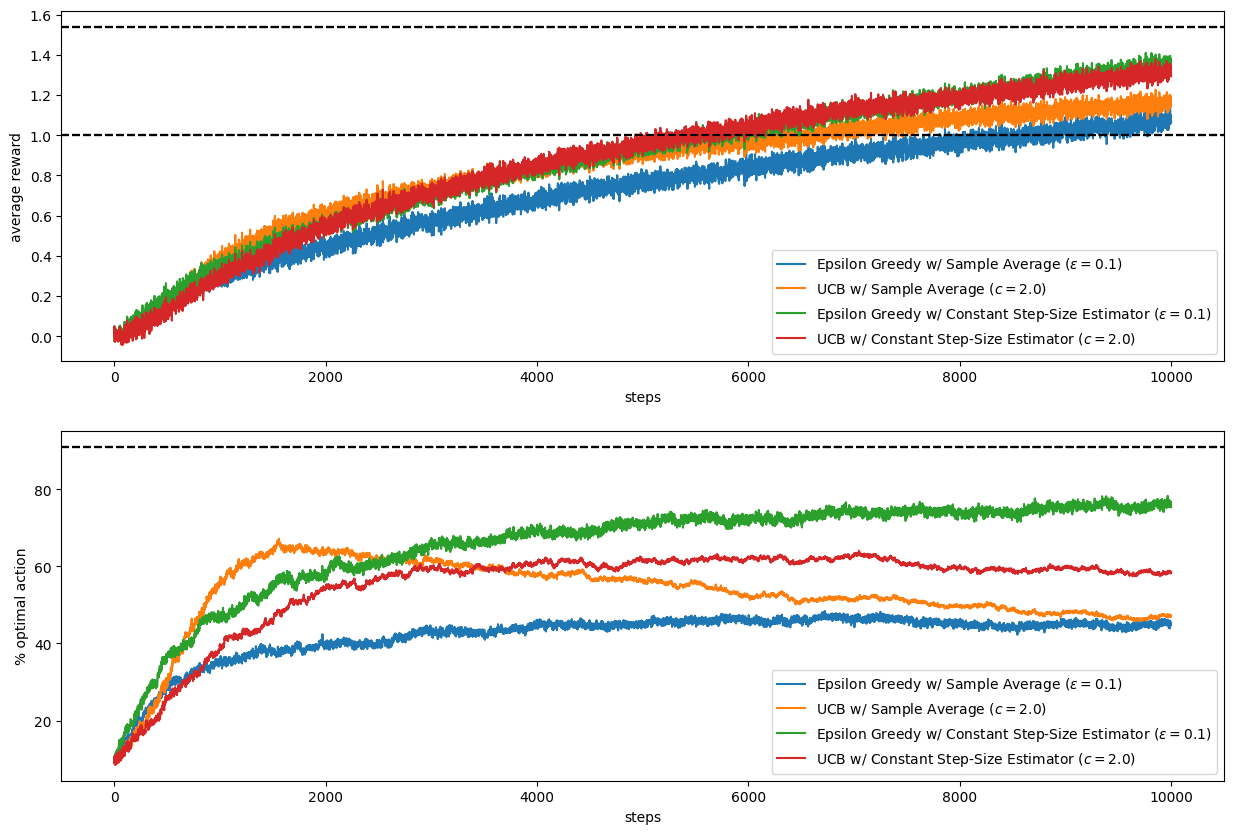

In [7]:
plt.figure(figsize=(15, 10))

plt.subplot(2, 1, 1)
for i, result in enumerate(results):
    plt.plot(result["average_rewards"], label=labels[i])
    plt.axhline(y=1.54, color='k', linestyle='--')
    plt.axhline(y=1, color='k', linestyle='--')
plt.xlabel("steps")
plt.ylabel("average reward")
plt.legend()

plt.subplot(2, 1, 2)
for i, result in enumerate(results):
    plt.plot(result["percent_optimal_actions"], label=labels[i])
    plt.axhline(y=91, color='k', linestyle='--')
plt.xlabel("steps")
plt.ylabel("% optimal action")
plt.legend()

# Gradient Bandit

In [8]:
%%time

# Estimator and Agent parameters
estimators = [SampleAverageEstimator, ConstantStepSizeEstimator, None]
agents =     [EpsilonGreedyAgent,     EpsilonGreedyAgent,        GradientBanditAgent]
epsilon = 0.1
alpha = 0.1
labels = [
    "Epsilon Greedy w/ Sample Average ($\\epsilon = %.01f$)" % (epsilon),
    "Epsilon Greedy w/ Constant Step-Size Estimator ($\\epsilon = %.01f$)" % (epsilon),
    "Gradient Bandit ($\\alpha = %.01f$)" % (alpha)
]

results = []

for estimator, agent in list(zip(estimators, agents)):
    results.append(
        run_experiment_parallel(
            R, T, k, 
            estimator, 
            agent,
            q_true_mean=q_true_mean, q_true_var=q_true_var, drift_var=drift_var,
            epsilon=epsilon,
            alpha=alpha
        )
    )

CPU times: user 17 s, sys: 2.8 s, total: 19.8 s
Wall time: 5min 2s


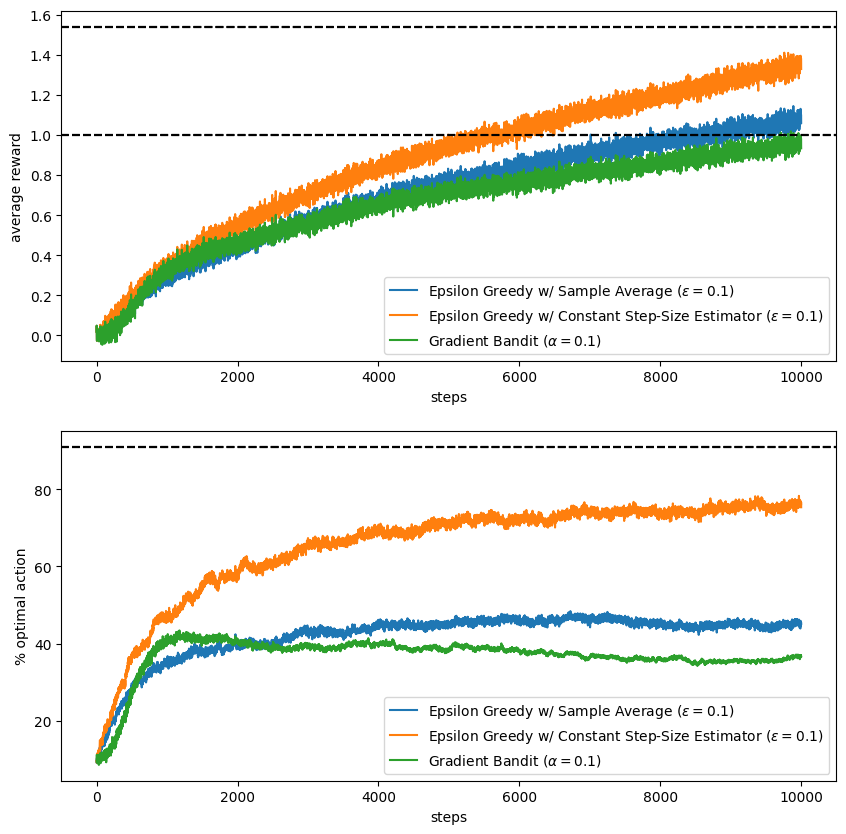

In [9]:
plt.figure(figsize=(10, 10))

plt.subplot(2, 1, 1)
for i, result in enumerate(results):
    plt.plot(result["average_rewards"], label=labels[i])
    plt.axhline(y=1.54, color='k', linestyle='--')
    plt.axhline(y=1, color='k', linestyle='--')
plt.xlabel("steps")
plt.ylabel("average reward")
plt.legend()

plt.subplot(2, 1, 2)
for i, result in enumerate(results):
    plt.plot(result["percent_optimal_actions"], label=labels[i])
    plt.axhline(y=91, color='k', linestyle='--')
plt.xlabel("steps")
plt.ylabel("% optimal action")
plt.legend()